# Solar Power Output Prediction Using Supervised Machine Learning

**CA-4 | Third-Year B.Tech CSE | Google Colab**

**Student Name:** Krishkumar Prajapati  
**Roll Number:** 24070721028  
**Batch:** CSE  
**Dataset:** Solar Power Generation Data

## Project Objective

The objective of this project is to analyse solar power generation data and develop supervised machine learning regression models to estimate plant-level AC power output using weather and time-related measurements.

This notebook is organised in the same academic workflow as a typical undergraduate case-study notebook: dataset overview, missing-value analysis, duplicate analysis, exploratory data analysis, correlation, outlier detection, feature engineering, baseline models, advanced models, cross-validation and final interpretation.


In [27]:
import os
import zipfile
import warnings
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
OUTPUT_DIR = Path("/content/solar_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


### Upload the dataset
Run this cell after the library-import cell completes. When the file picker opens, select the ZIP file downloaded from Kaggle.

In [28]:
import zipfile
from io import BytesIO
from pathlib import Path
import pandas as pd

zip_path = Path("/content/archive.zip")
if not zip_path.exists():
    raise FileNotFoundError("The dataset ZIP file '/content/archive.zip' was not found. Please place it in the /content folder.")

EXTRACT_DIR = Path("/content/solar_dataset")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

csv_paths = list(EXTRACT_DIR.rglob("*.csv"))

print("\nCSV files found:")
for path in csv_paths:
    print("-", path.name)

def find_csv(keyword):
    matches = [p for p in csv_paths if keyword.lower() in p.name.lower()]
    if not matches:
        raise FileNotFoundError(
            f"Could not find a CSV file containing '{keyword}'. "
            "Check the filenames printed above."
        )
    return matches[0]

gen1 = pd.read_csv(find_csv("Plant_1_Generation"))
weather1 = pd.read_csv(find_csv("Plant_1_Weather"))
gen2 = pd.read_csv(find_csv("Plant_2_Generation"))
weather2 = pd.read_csv(find_csv("Plant_2_Weather"))

print("\nAll four files loaded successfully.")
print("Plant 1 generation:", gen1.shape)
print("Plant 1 weather:", weather1.shape)
print("Plant 2 generation:", gen2.shape)
print("Plant 2 weather:", weather2.shape)


CSV files found:
- Plant_2_Generation_Data.csv
- Plant_1_Generation_Data.csv
- Plant_2_Weather_Sensor_Data.csv
- Plant_1_Weather_Sensor_Data.csv

All four files loaded successfully.
Plant 1 generation: (68778, 7)
Plant 1 weather: (3182, 6)
Plant 2 generation: (67698, 7)
Plant 2 weather: (3259, 6)


## 1. Dataset Overview and Statistical Summary

The original dataset contains inverter-level generation records and weather sensor readings for two solar plants. The generation files contain power and yield measurements, while the weather files contain irradiation and temperature measurements.

For modelling, inverter-level `AC_POWER` readings are aggregated by plant and timestamp. Weather readings are averaged for the same plant and timestamp. This creates one row per plant-time observation.

The following summaries describe the raw files before aggregation.

In [29]:
raw_datasets = {
    "Plant 1 Generation": gen1,
    "Plant 1 Weather": weather1,
    "Plant 2 Generation": gen2,
    "Plant 2 Weather": weather2
}

for name, frame in raw_datasets.items():
    print(f"\n{name}")
    print("Shape:", frame.shape)
    print("Columns:", frame.columns.tolist())
    display(frame.head(3))

print("\nPlant 1 Generation - information:")
gen1.info()

print("\nPlant 1 Generation - numerical summary:")
display(gen1.describe().T)

print("\nPlant 1 Weather - numerical summary:")
display(weather1.describe().T)


Plant 1 Generation
Shape: (68778, 7)
Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0



Plant 1 Weather
Shape: (3182, 6)
Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0



Plant 2 Generation
Shape: (67698, 7)
Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15 00:00:00,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06
1,2020-05-15 00:00:00,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09
2,2020-05-15 00:00:00,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09


... (2 outputs left out)


Plant 1 Generation - information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  object 
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  object 
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 3.7+ MB

Plant 1 Generation - numerical summary:


,count,mean,std,min,25%,50%,75%,max
PLANT_ID,68778.0,4.135001e+06,0.000000,4135001.0,4.135001e+06,4.135001e+06,4.135001e+06,4135001.000
DC_POWER,68778.0,3.147426e+03,4036.457169,0.0,0.000000e+00,4.290000e+02,6.366964e+03,14471.125
AC_POWER,68778.0,3.078028e+02,394.396439,0.0,0.000000e+00,4.149375e+01,6.236187e+02,1410.950
DAILY_YIELD,68778.0,3.295969e+03,3145.178309,0.0,0.000000e+00,2.658714e+03,6.274000e+03,9163.000
TOTAL_YIELD,68778.0,6.978712e+06,416271.982856,6183645.0,6.512003e+06,7.146685e+06,7.268706e+06,7846821.000



Plant 1 Weather - numerical summary:


,count,mean,std,min,25%,50%,75%,max
PLANT_ID,3182.0,4.135001e+06,0.000000,4.135001e+06,4.135001e+06,4.135001e+06,4.135001e+06,4.135001e+06
AMBIENT_TEMPERATURE,3182.0,2.553161e+01,3.354856,2.039850e+01,2.270518e+01,2.461381e+01,2.792053e+01,3.525249e+01
MODULE_TEMPERATURE,3182.0,3.109102e+01,12.261222,1.814042e+01,2.109055e+01,2.461806e+01,4.130784e+01,6.554571e+01
IRRADIATION,3182.0,2.283128e-01,0.300836,0.000000e+00,0.000000e+00,2.465348e-02,4.495884e-01,1.221652e+00


## 2. Missing Value Analysis

Missing values are checked separately in each source file. This is important because generation and weather records are collected independently. The percentage column makes it easier to compare missingness across files of different sizes.

In [30]:
def missing_value_summary(frame, dataset_name):
    summary = pd.DataFrame({
        "Missing Values": frame.isna().sum(),
        "Missing Percentage": (frame.isna().mean() * 100).round(2)
    })
    summary = summary[summary["Missing Values"] > 0]
    print(f"\n{dataset_name}")
    if summary.empty:
        print("No missing values detected.")
    else:
        display(summary.sort_values("Missing Percentage", ascending=False))
    return summary

missing_summaries = {
    name: missing_value_summary(frame, name)
    for name, frame in raw_datasets.items()
}


Plant 1 Generation
No missing values detected.

Plant 1 Weather
No missing values detected.

Plant 2 Generation
No missing values detected.

Plant 2 Weather
No missing values detected.


In [31]:
missing_plot_rows = []

for name, frame in raw_datasets.items():
    percentages = frame.isna().mean().mul(100)
    for column, percentage in percentages.items():
        if percentage > 0:
            missing_plot_rows.append({
                "Dataset": name,
                "Feature": column,
                "Missing Percentage": percentage
            })

missing_plot = pd.DataFrame(missing_plot_rows)

if not missing_plot.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(
        data=missing_plot,
        x="Feature",
        y="Missing Percentage",
        hue="Dataset"
    )
    plt.title("Missing Value Percentage in Raw Dataset Files")
    plt.xlabel("Feature")
    plt.ylabel("Missing Percentage (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "missing_values.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No missing values found in the four raw files.")

No missing values found in the four raw files.


### Missing Value Interpretation

Use the summaries above to identify which source files and columns contain missing values. Missing values will be handled after the generation and weather records are combined. Numeric input features will be imputed inside the modelling pipeline using the training data only. Rows without a valid target value will not be used for supervised training.

## 3. Duplicate Record Analysis

Duplicate rows are checked in each raw file. We also check whether the plant-time keys repeat in the weather data. Repeated inverter timestamps in generation data are expected because a plant can contain multiple inverters; they are aggregated rather than treated as duplicate plant observations.

In [32]:
for name, frame in raw_datasets.items():
    print(f"{name}: {frame.duplicated().sum()} exact duplicate rows")

for name, frame in [
    ("Plant 1 Weather", weather1),
    ("Plant 2 Weather", weather2)
]:
    if {"DATE_TIME", "PLANT_ID"}.issubset(frame.columns):
        key_duplicates = frame.duplicated(subset=["DATE_TIME", "PLANT_ID"]).sum()
        print(f"{name}: {key_duplicates} repeated plant-time keys")

Plant 1 Generation: 0 exact duplicate rows
Plant 1 Weather: 0 exact duplicate rows
Plant 2 Generation: 0 exact duplicate rows
Plant 2 Weather: 0 exact duplicate rows
Plant 1 Weather: 0 repeated plant-time keys
Plant 2 Weather: 0 repeated plant-time keys


## 4. Prepare the Plant-Level Modelling Dataset

The generation data has one row per inverter and timestamp. We sum inverter `AC_POWER` values to estimate total plant AC output at that timestamp. Weather sensor readings are averaged by timestamp and plant. The two data sources are then merged using `DATE_TIME` and `PLANT_ID`.

`DC_POWER`, `DAILY_YIELD` and `TOTAL_YIELD` are not used as predictors. They are closely related to power generation and could introduce target leakage into the model.

In [33]:
def prepare_plant(generation, weather, plant_name):
    generation = generation.copy()
    weather = weather.copy()

    generation["DATE_TIME"] = pd.to_datetime(
        generation["DATE_TIME"], errors="coerce"
    )
    weather["DATE_TIME"] = pd.to_datetime(
        weather["DATE_TIME"], errors="coerce"
    )

    generation_agg = (
        generation.dropna(subset=["DATE_TIME"])
        .groupby(["DATE_TIME", "PLANT_ID"], as_index=False)
        .agg(AC_POWER=("AC_POWER", "sum"))
    )

    weather_features = [
        "AMBIENT_TEMPERATURE",
        "MODULE_TEMPERATURE",
        "IRRADIATION"
    ]

    weather_agg = (
        weather.dropna(subset=["DATE_TIME"])
        .groupby(["DATE_TIME", "PLANT_ID"], as_index=False)[weather_features]
        .mean()
    )

    merged = generation_agg.merge(
        weather_agg,
        on=["DATE_TIME", "PLANT_ID"],
        how="inner",
        validate="one_to_one"
    )
    merged["PLANT"] = plant_name
    return merged

plant1_data = prepare_plant(gen1, weather1, "Plant 1")
plant2_data = prepare_plant(gen2, weather2, "Plant 2")

df = pd.concat([plant1_data, plant2_data], ignore_index=True)
df = df.sort_values(["DATE_TIME", "PLANT_ID"]).reset_index(drop=True)

print("Combined plant-level dataset shape:", df.shape)
print("Date range:", df["DATE_TIME"].min(), "to", df["DATE_TIME"].max())
print("Plants:", df["PLANT"].unique())
display(df.head())

Combined plant-level dataset shape: (6416, 7)
Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plants: ['Plant 1' 'Plant 2']


,DATE_TIME,PLANT_ID,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT
0,2020-05-15 00:00:00,4135001,0.0,25.184316,22.857507,0.0,Plant 1
1,2020-05-15 00:00:00,4136001,0.0,27.004764,25.060789,0.0,Plant 2
2,2020-05-15 00:15:00,4135001,0.0,25.084589,22.761668,0.0,Plant 1
3,2020-05-15 00:15:00,4136001,0.0,26.880811,24.421869,0.0,Plant 2
4,2020-05-15 00:30:00,4135001,0.0,24.935753,22.592306,0.0,Plant 1


## 5. Dataset-Level Missing Values and Cleaning

After merging, inspect missing values again. Negative irradiation values are not physically meaningful for this dataset, so they are treated as missing. Temperature values are not automatically removed based only on their sign. Rows with missing target values are removed because the model cannot learn a target that is not available. Other missing input values are handled later within each model pipeline.

In [34]:
print("Missing values in merged dataset:")
missing_count = df.isna().sum()
missing_percentage = (df.isna().mean() * 100).round(2)

missing_data = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})
display(missing_data)

df.loc[df["IRRADIATION"] < 0, "IRRADIATION"] = np.nan

before_rows = len(df)
df = df.dropna(subset=["AC_POWER", "DATE_TIME"]).copy()

negative_target_count = (df["AC_POWER"] < 0).sum()
print("Negative AC_POWER records:", negative_target_count)
df = df[df["AC_POWER"] >= 0].copy()

print("Rows before target cleaning:", before_rows)
print("Rows after target cleaning:", len(df))
print("\nMissing values after basic cleaning:")
display(df.isna().sum().to_frame("Missing Values"))

Missing values in merged dataset:


,Missing Values,Missing Percentage
DATE_TIME,0,0.0
PLANT_ID,0,0.0
AC_POWER,0,0.0
AMBIENT_TEMPERATURE,0,0.0
MODULE_TEMPERATURE,0,0.0
IRRADIATION,0,0.0
PLANT,0,0.0


Negative AC_POWER records: 0
Rows before target cleaning: 6416
Rows after target cleaning: 6416

Missing values after basic cleaning:


,Missing Values
DATE_TIME,0
PLANT_ID,0
AC_POWER,0
AMBIENT_TEMPERATURE,0
MODULE_TEMPERATURE,0
IRRADIATION,0
PLANT,0


## 6. Target Variable Distribution Analysis

The target variable is aggregated `AC_POWER`. Its distribution helps us understand the range of solar generation values and the frequency of low-output observations, including periods when little or no solar energy is generated.

AC_POWER statistical summary:


,AC_POWER
count,6416.000000
mean,5844.946416
std,7576.958173
min,0.000000
25%,0.000000
50%,638.473810
75%,11898.456667
max,29150.212499


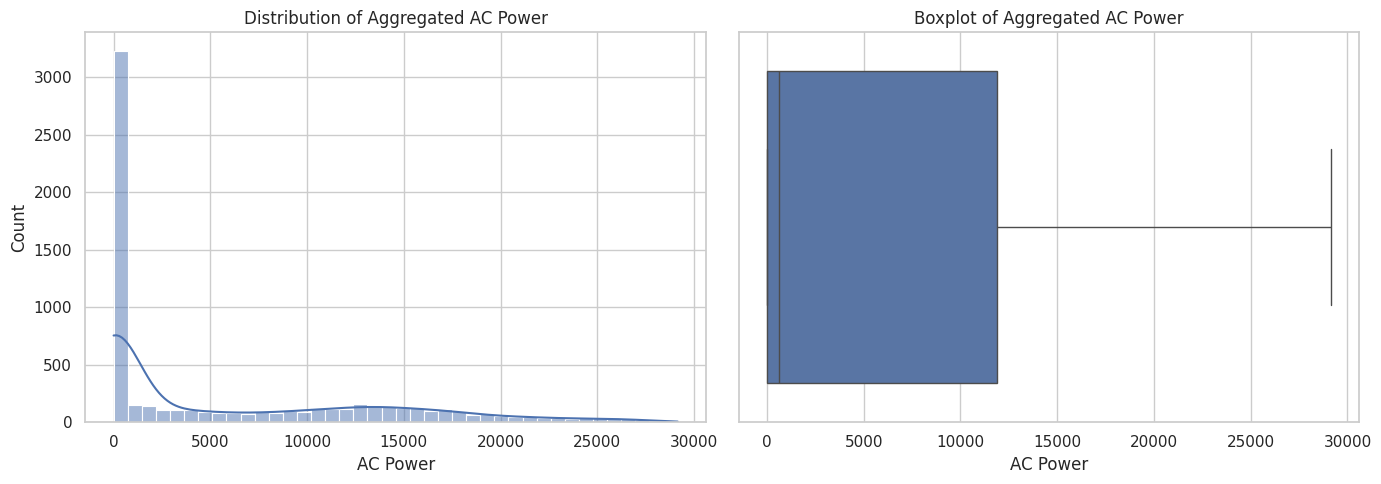

In [35]:
print("AC_POWER statistical summary:")
display(df["AC_POWER"].describe().to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="AC_POWER", bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Aggregated AC Power")
axes[0].set_xlabel("AC Power")

sns.boxplot(data=df, x="AC_POWER", ax=axes[1])
axes[1].set_title("Boxplot of Aggregated AC Power")
axes[1].set_xlabel("AC Power")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Weather Feature Distribution Analysis

The weather variables used in this study are irradiation, ambient temperature and module temperature. Their distributions are inspected to understand their ranges and identify possible skewness or unusual observations.

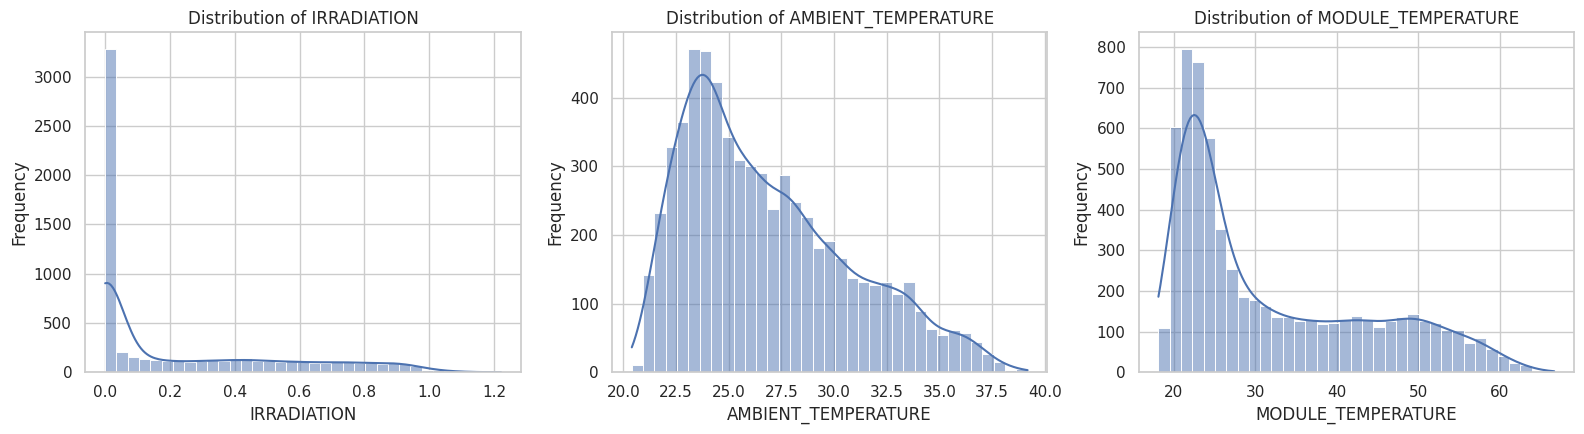

In [36]:
weather_features = [
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for feature, ax in zip(weather_features, axes):
    sns.histplot(data=df, x=feature, bins=35, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "weather_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Relationship Between Weather Features and AC Power

Scatter plots are used to inspect the relationship between each weather measurement and AC power. A sample is used for plotting when the dataset is large, so the visualisations remain readable. The full dataset is still used for model training.

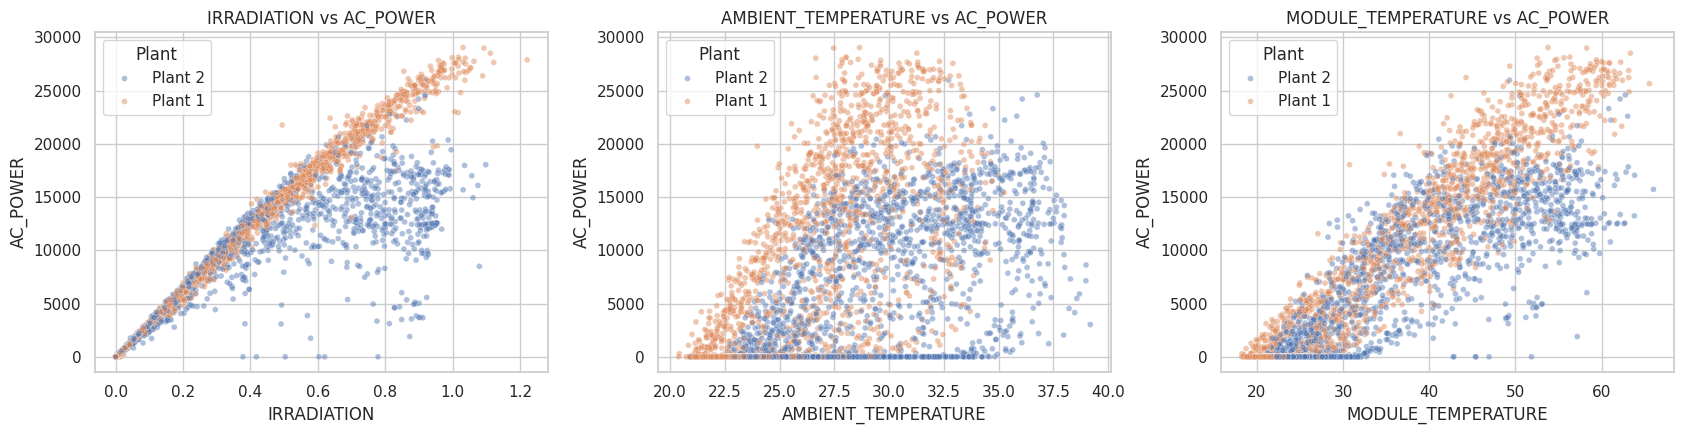

In [37]:
plot_sample = df.sample(
    n=min(5000, len(df)),
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for feature, ax in zip(weather_features, axes):
    sns.scatterplot(
        data=plot_sample,
        x=feature,
        y="AC_POWER",
        hue="PLANT",
        alpha=0.45,
        s=18,
        ax=ax
    )
    ax.set_title(f"{feature} vs AC_POWER")
    ax.legend(title="Plant")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "weather_vs_ac_power.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Plant-Wise and Time-Based Analysis

The dataset includes two plants. Comparing their output distributions and the average output by hour can reveal differences between the plants and the daily generation pattern.

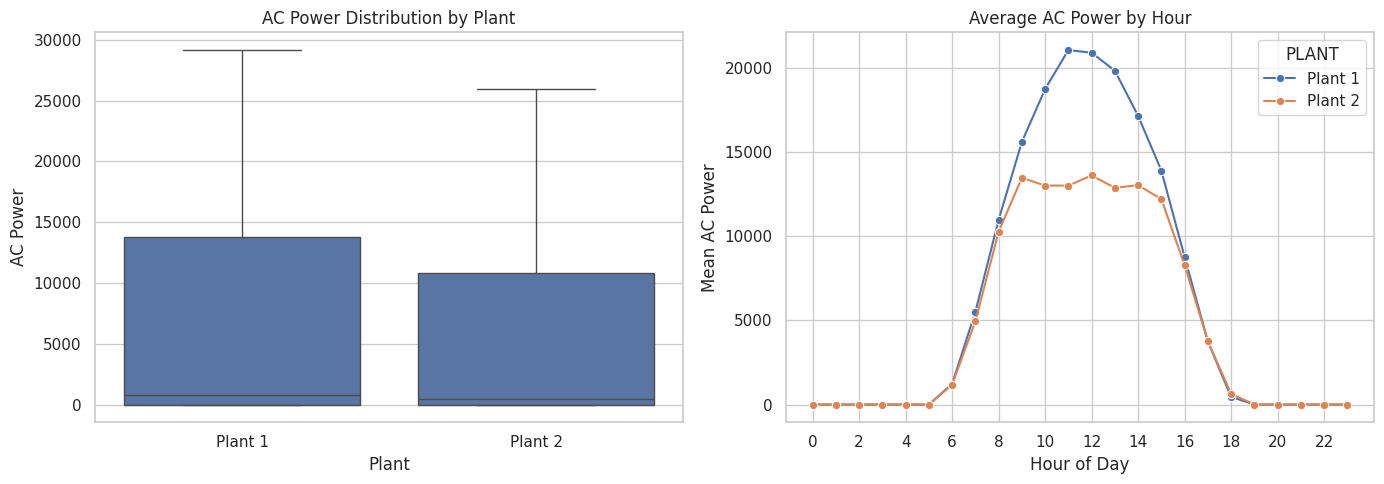

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="PLANT", y="AC_POWER", ax=axes[0])
axes[0].set_title("AC Power Distribution by Plant")
axes[0].set_xlabel("Plant")
axes[0].set_ylabel("AC Power")

df["HOUR"] = df["DATE_TIME"].dt.hour
hourly_output = df.groupby(["PLANT", "HOUR"], as_index=False)["AC_POWER"].mean()

sns.lineplot(data=hourly_output, x="HOUR", y="AC_POWER",
             hue="PLANT", marker="o", ax=axes[1])
axes[1].set_title("Average AC Power by Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Mean AC Power")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "plant_and_hour_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Correlation Analysis

Pearson correlation is calculated for numerical variables. It describes the strength and direction of linear association in this dataset; it does not prove that one variable causes another. `PLANT_ID` is treated as an identifier/category rather than a continuous measurement.

,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
AC_POWER,1.000,0.938,0.593,0.903
IRRADIATION,0.938,1.000,0.655,0.951
AMBIENT_TEMPERATURE,0.593,0.655,1.000,0.818
MODULE_TEMPERATURE,0.903,0.951,0.818,1.000


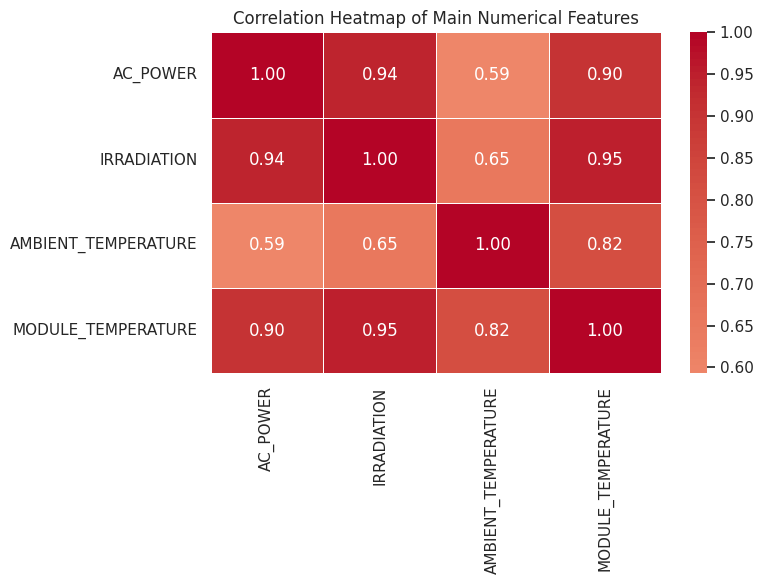

In [39]:
correlation_columns = [
    "AC_POWER",
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

correlation_matrix = df[correlation_columns].corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Correlation Heatmap of Main Numerical Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Outlier Detection Using the IQR Method

The Interquartile Range (IQR) method flags observations below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Outliers are identified for inspection, not automatically removed. High irradiation or temperature readings can be genuine operating conditions, and removing them without domain justification could reduce useful information.

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,AC_POWER,-17847.69,29746.14,0,0.00
1,IRRADIATION,-0.67,1.11,3,0.05
2,AMBIENT_TEMPERATURE,15.13,37.91,15,0.23
3,MODULE_TEMPERATURE,-5.23,68.63,0,0.00


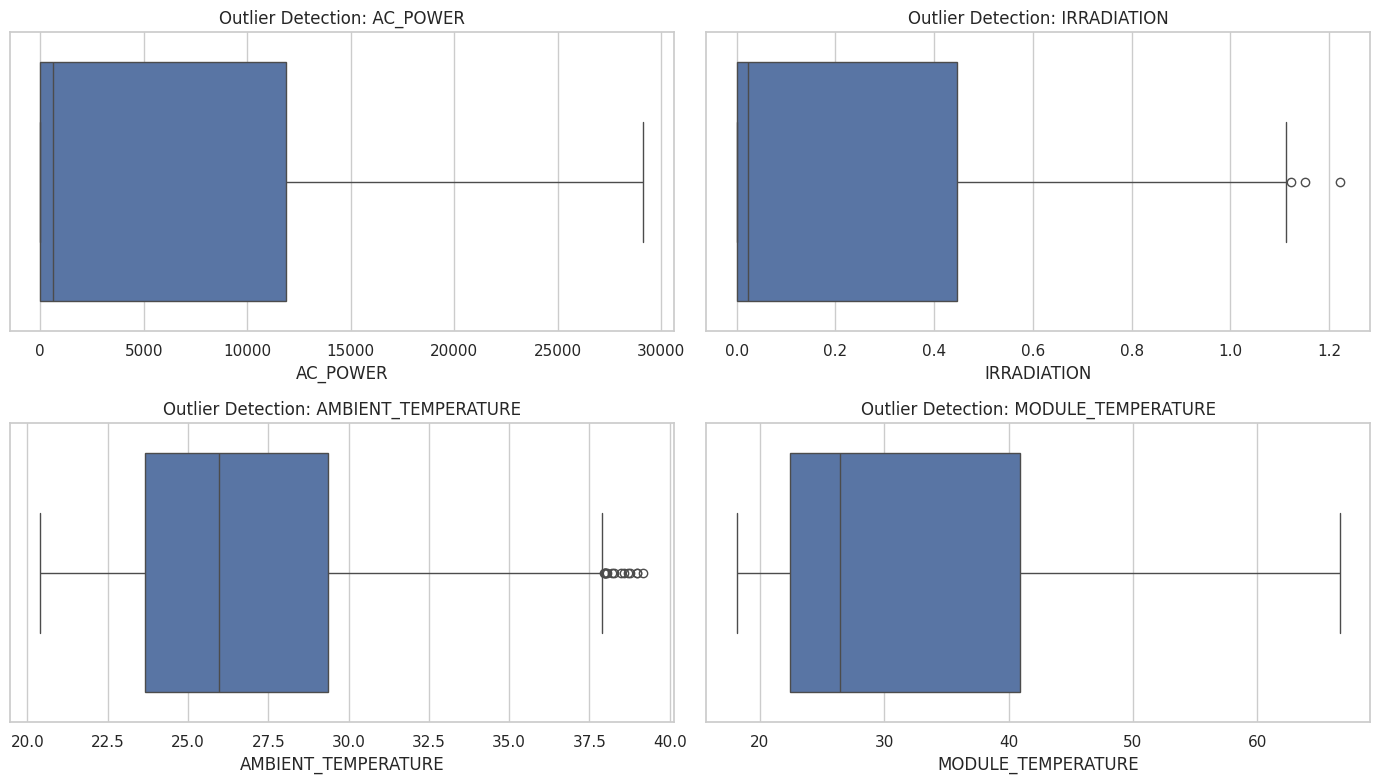

In [40]:
outlier_features = [
    "AC_POWER",
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

outlier_rows = []

for feature in outlier_features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = ((df[feature] < lower_bound) | (df[feature] > upper_bound)).sum()

    outlier_rows.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": count,
        "Outlier Percentage": count / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for feature, ax in zip(outlier_features, axes.flatten()):
    sns.boxplot(data=df, x=feature, ax=ax)
    ax.set_title(f"Outlier Detection: {feature}")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "outlier_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Feature Engineering

Time-based features are extracted from the timestamp. Hour is represented using sine and cosine transformations because time is cyclical: 23:00 is close to 00:00. Plant is retained as a categorical feature.

The model predictors do not include `DC_POWER`, `DAILY_YIELD` or `TOTAL_YIELD`, which could reveal information about the target.

In [41]:
df["HOUR"] = df["DATE_TIME"].dt.hour
df["DAY_OF_WEEK"] = df["DATE_TIME"].dt.dayofweek
df["MONTH"] = df["DATE_TIME"].dt.month
df["DAY_OF_YEAR"] = df["DATE_TIME"].dt.dayofyear

df["HOUR_SIN"] = np.sin(2 * np.pi * df["HOUR"] / 24)
df["HOUR_COS"] = np.cos(2 * np.pi * df["HOUR"] / 24)

print("Engineered feature preview:")
display(df[[
    "DATE_TIME", "PLANT", "HOUR", "DAY_OF_WEEK",
    "HOUR_SIN", "HOUR_COS", "AC_POWER"
]].head(10))

Engineered feature preview:


,DATE_TIME,PLANT,HOUR,DAY_OF_WEEK,HOUR_SIN,HOUR_COS,AC_POWER
0,2020-05-15 00:00:00,Plant 1,0,4,0.000000,1.000000,0.0
1,2020-05-15 00:00:00,Plant 2,0,4,0.000000,1.000000,0.0
2,2020-05-15 00:15:00,Plant 1,0,4,0.000000,1.000000,0.0
3,2020-05-15 00:15:00,Plant 2,0,4,0.000000,1.000000,0.0
4,2020-05-15 00:30:00,Plant 1,0,4,0.000000,1.000000,0.0
5,2020-05-15 00:30:00,Plant 2,0,4,0.000000,1.000000,0.0
6,2020-05-15 00:45:00,Plant 1,0,4,0.000000,1.000000,0.0
7,2020-05-15 00:45:00,Plant 2,0,4,0.000000,1.000000,0.0
8,2020-05-15 01:00:00,Plant 1,1,4,0.258819,0.965926,0.0
9,2020-05-15 01:00:00,Plant 2,1,4,0.258819,0.965926,0.0


## 13. Baseline Regression Models

The target is continuous, so this is a regression problem. The data is divided chronologically into 70% training data and 30% testing data. All observations from the same timestamp are kept on the same side of the split. This reduces the risk of using later observations to predict earlier ones.

The required baseline models are Linear Regression, Decision Tree Regressor and KNN Regressor. Random Forest and Gradient Boosting are also included as advanced ensemble models.

Numeric imputation, scaling and categorical encoding are kept inside scikit-learn pipelines. This ensures that preprocessing is learned from training data rather than the test set.

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

feature_columns = [
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "HOUR_SIN",
    "HOUR_COS",
    "DAY_OF_WEEK",
    "MONTH",
    "DAY_OF_YEAR",
    "PLANT"
]
target_column = "AC_POWER"

model_df = df[["DATE_TIME"] + feature_columns + [target_column]].copy()
model_df = model_df.dropna(subset=[target_column]).sort_values("DATE_TIME")

unique_timestamps = np.sort(model_df["DATE_TIME"].unique())
split_index = int(len(unique_timestamps) * 0.70)
split_timestamp = unique_timestamps[split_index]

train_df = model_df[model_df["DATE_TIME"] < split_timestamp].copy()
test_df = model_df[model_df["DATE_TIME"] >= split_timestamp].copy()

X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()
X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

print("Split timestamp:", split_timestamp)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training share:", round(len(X_train) / len(model_df) * 100, 2), "%")
print("Testing share:", round(len(X_test) / len(model_df) * 100, 2), "%")

numeric_features = [
    "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE",
    "HOUR_SIN", "HOUR_COS", "DAY_OF_WEEK", "MONTH", "DAY_OF_YEAR"
]
categorical_features = ["PLANT"]

numeric_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
numeric_unscaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer(transformers=[
    ("num", numeric_scaled, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
preprocessor_unscaled = ColumnTransformer(transformers=[
    ("num", numeric_unscaled, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Linear Regression": Pipeline([
        ("preprocess", preprocessor_scaled),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", preprocessor_unscaled),
        ("model", DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("preprocess", preprocessor_scaled),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor_unscaled),
        ("model", RandomForestRegressor(
            n_estimators=120, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocess", preprocessor_unscaled),
        ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))
    ])
}

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2 Score": r2_score(y_true, y_pred)
    }

baseline_rows = []
fitted_models = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    fitted_models[name] = pipeline
    baseline_rows.append({
        "Model": name,
        **regression_metrics(y_test, predictions)
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("RMSE")
display(baseline_results.round(4))

Split timestamp: 2020-06-07T19:15:00.000000000
Training rows: 4460
Testing rows: 1956
Training share: 69.51 %
Testing share: 30.49 %


,Model,MAE,RMSE,R2 Score
4,Gradient Boosting,582.3012,1372.7995,0.9626
3,Random Forest,521.0879,1402.7370,0.9609
2,KNN,830.1358,1715.5564,0.9415
1,Decision Tree,651.4264,1769.6437,0.9378
0,Linear Regression,1525.3590,2225.5005,0.9016


### Baseline Model Interpretation

Compare the models using MAE, RMSE and R². Lower MAE and RMSE indicate smaller prediction errors, while a higher R² indicates that the model explains more variation in AC power. No model should be declared best until the actual results have been generated and compared.

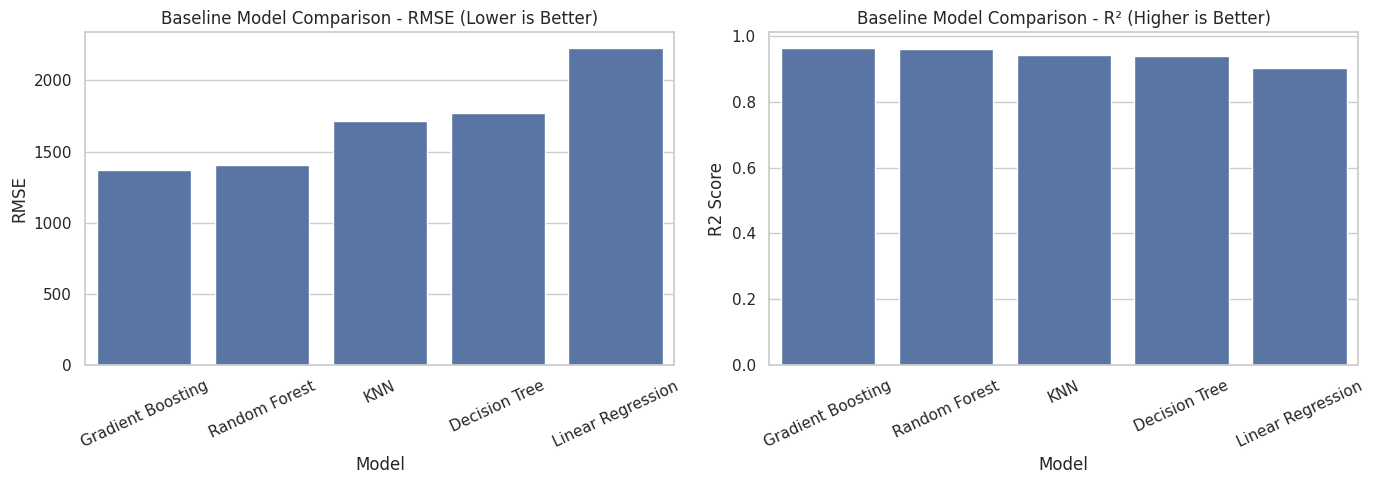

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=baseline_results, x="Model", y="RMSE", ax=axes[0])
axes[0].set_title("Baseline Model Comparison - RMSE (Lower is Better)")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(data=baseline_results, x="Model", y="R2 Score", ax=axes[1])
axes[1].set_title("Baseline Model Comparison - R² (Higher is Better)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baseline_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 14. Advanced Models and Hyperparameter Optimisation

Random Forest and Gradient Boosting are tuned using `GridSearchCV`. `TimeSeriesSplit` is used so each validation fold respects the time order. The test partition is not used during parameter selection.

The parameter grids are kept reasonably small so that the notebook can run within a typical Google Colab session.

In [44]:
time_cv = TimeSeriesSplit(n_splits=5)

rf_pipeline = Pipeline([
    ("preprocess", preprocessor_unscaled),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

rf_parameter_grid = {
    "model__n_estimators": [100, 150],
    "model__max_depth": [10, None],
    "model__min_samples_split": [2, 5]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=time_cv,
    n_jobs=-1,
    verbose=1
)
rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Best training CV RMSE:", -rf_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Random Forest parameters:
{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best training CV RMSE: 1817.1041380460852


In [45]:
gb_pipeline = Pipeline([
    ("preprocess", preprocessor_unscaled),
    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))
])

gb_parameter_grid = {
    "model__n_estimators": [100, 150],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

gb_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=time_cv,
    n_jobs=-1,
    verbose=1
)
gb_search.fit(X_train, y_train)

print("Best Gradient Boosting parameters:")
print(gb_search.best_params_)
print("Best training CV RMSE:", -gb_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Gradient Boosting parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}
Best training CV RMSE: 1795.2906745884443


## 15. Cross-Validation Analysis

Cross-validation provides a more stable view of model performance than relying on one training/validation split. Five-fold time-series cross-validation is applied to the training partition. The test partition remains separate for final evaluation.

In [46]:
cv_rows = []

for model_name, pipeline in fitted_models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=time_cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False
    )

    cv_rows.append({
        "Model": model_name,
        "CV MAE Mean": -scores["test_mae"].mean(),
        "CV MAE Std": scores["test_mae"].std(ddof=0),
        "CV RMSE Mean": -scores["test_rmse"].mean(),
        "CV RMSE Std": scores["test_rmse"].std(ddof=0),
        "CV R2 Mean": scores["test_r2"].mean()
    })

for label, search in [
    ("Random Forest (Tuned)", rf_search),
    ("Gradient Boosting (Tuned)", gb_search)
]:
    idx = search.best_index_
    cv_rows.append({
        "Model": label,
        "CV MAE Mean": np.nan,
        "CV MAE Std": np.nan,
        "CV RMSE Mean": -search.cv_results_["mean_test_score"][idx],
        "CV RMSE Std": search.cv_results_["std_test_score"][idx],
        "CV R2 Mean": np.nan
    })

cv_summary = pd.DataFrame(cv_rows).set_index("Model")
display(cv_summary.round(4))

,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean
Model,,,,,
Linear Regression,1661.6614,107.4928,2670.3853,525.1106,0.8757
Decision Tree,868.4423,105.5996,2140.9767,335.8014,0.9228
KNN,1130.3642,209.8333,2133.0459,408.9841,0.9204
Random Forest,716.2636,120.8675,1810.9373,354.1644,0.9429
Gradient Boosting,768.6937,120.0916,1814.7520,395.4885,0.9420
Random Forest (Tuned),NaN,NaN,1817.1041,350.1393,NaN
Gradient Boosting (Tuned),NaN,NaN,1795.2907,410.5186,NaN


## 16. Final Model Comparison on the Held-Out Test Set

The baseline models and tuned ensemble models are evaluated on the same chronological test partition. MAE, RMSE and R² are reported for every model. The model with the lowest test RMSE is highlighted for residual and feature-importance analysis, while cross-validation results should also be considered when discussing model stability.

In [47]:
selected_models = {
    **fitted_models,
    "Random Forest (Tuned)": rf_search.best_estimator_,
    "Gradient Boosting (Tuned)": gb_search.best_estimator_
}

final_rows = []
test_predictions = {}

for name, pipeline in selected_models.items():
    prediction = pipeline.predict(X_test)
    test_predictions[name] = prediction
    final_rows.append({
        "Model": name,
        **regression_metrics(y_test, prediction)
    })

final_comparison = pd.DataFrame(final_rows).sort_values("RMSE").reset_index(drop=True)
display(final_comparison.round(4))

best_model_name = final_comparison.loc[0, "Model"]
best_model = selected_models[best_model_name]
best_predictions = test_predictions[best_model_name]

print("Best model by held-out RMSE:", best_model_name)

,Model,MAE,RMSE,R2 Score
0,Gradient Boosting (Tuned),554.2153,1333.6102,0.9647
1,Gradient Boosting,582.3012,1372.7995,0.9626
2,Random Forest,521.0879,1402.7370,0.9609
3,Random Forest (Tuned),525.5522,1411.5506,0.9604
4,KNN,830.1358,1715.5564,0.9415
5,Decision Tree,651.4264,1769.6437,0.9378
6,Linear Regression,1525.3590,2225.5005,0.9016


Best model by held-out RMSE: Gradient Boosting (Tuned)


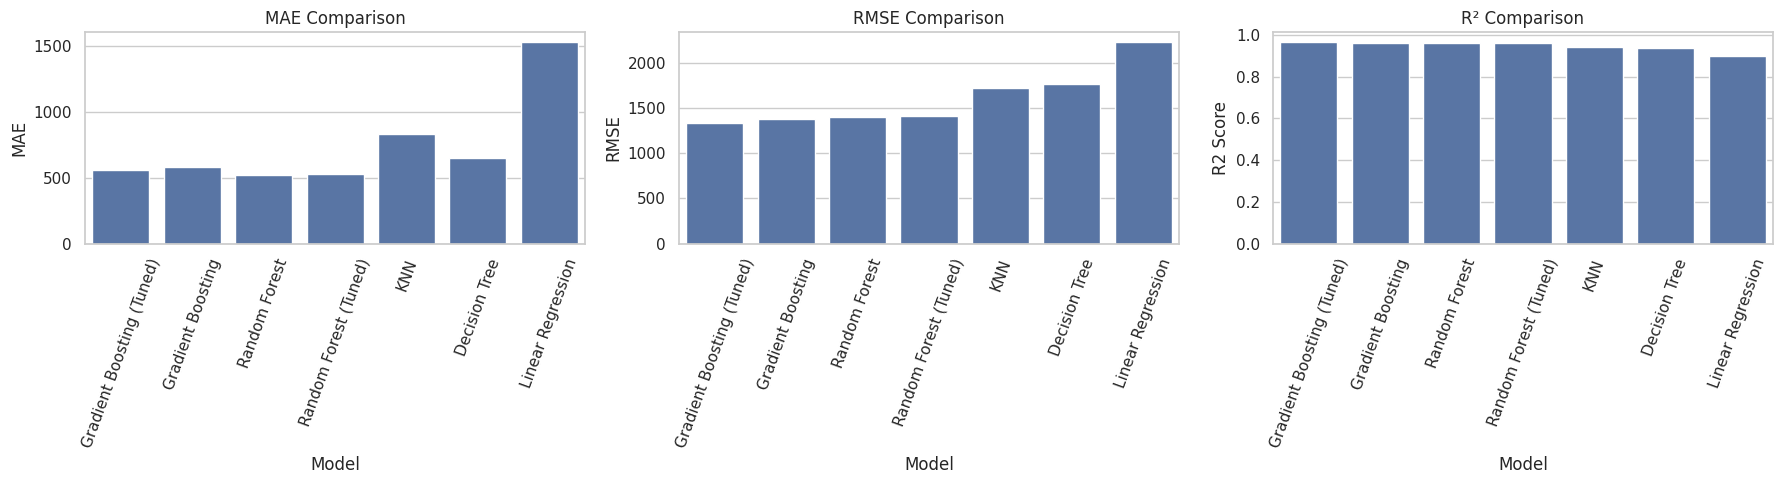

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=final_comparison, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE Comparison")
axes[0].tick_params(axis="x", rotation=70)

sns.barplot(data=final_comparison, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE Comparison")
axes[1].tick_params(axis="x", rotation=70)

sns.barplot(data=final_comparison, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("R² Comparison")
axes[2].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "final_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 17. Actual vs Predicted Values and Residual Analysis

An actual-versus-predicted plot shows how closely the model estimates follow the observed values. Residuals are calculated as actual AC power minus predicted AC power. Residual plots help identify systematic errors, such as consistently overpredicting or underpredicting certain output ranges.

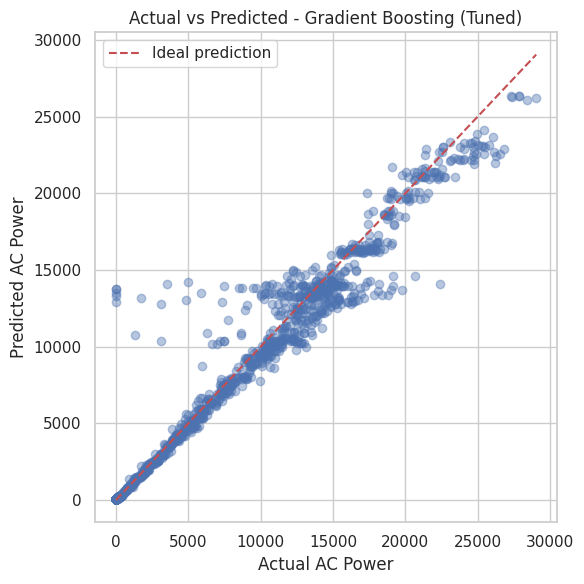

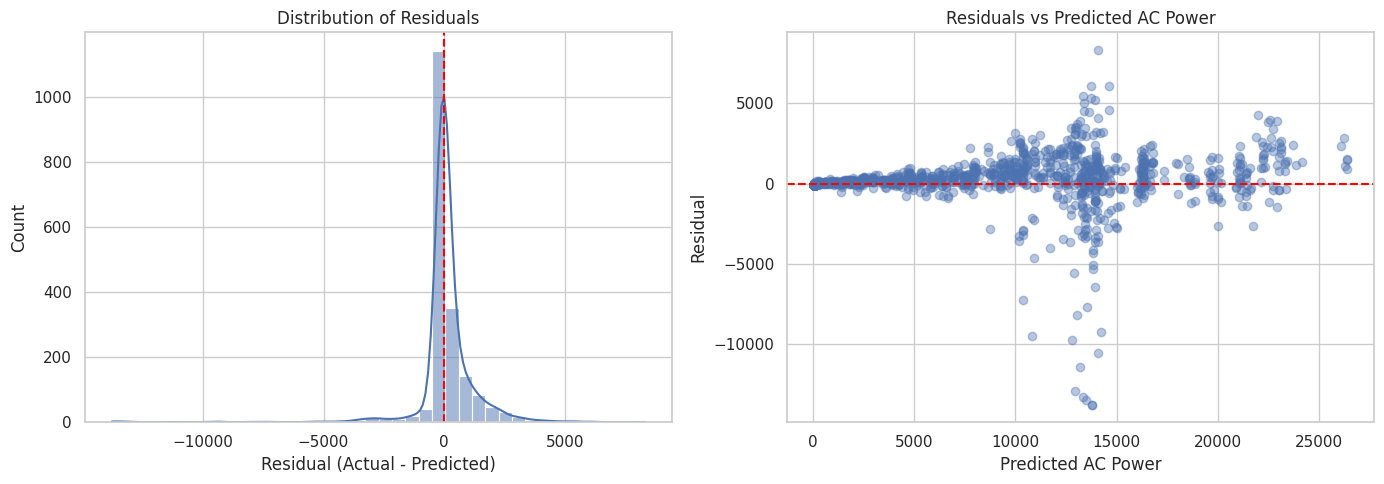

Final test metrics:


,MAE,RMSE,R2 Score
Gradient Boosting (Tuned),554.2153,1333.6102,0.9647


In [49]:
residuals = y_test - best_predictions

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.4)
line_min = min(y_test.min(), best_predictions.min())
line_max = max(y_test.max(), best_predictions.max())
plt.plot([line_min, line_max], [line_min, line_max], "r--", label="Ideal prediction")
plt.xlabel("Actual AC Power")
plt.ylabel("Predicted AC Power")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, bins=40, kde=True, ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Distribution of Residuals")
axes[0].set_xlabel("Residual (Actual - Predicted)")

axes[1].scatter(best_predictions, residuals, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted AC Power")
axes[1].set_xlabel("Predicted AC Power")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "residual_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Final test metrics:")
display(pd.DataFrame([regression_metrics(y_test, best_predictions)], index=[best_model_name]).round(4))

## 18. Feature Importance Analysis

Permutation importance measures how much the model's evaluation score changes when one input feature is shuffled. It provides an interpretable estimate of which inputs the fitted model relies on. Feature importance describes model behaviour and should not be interpreted as proof of causation.

,Feature,Importance Mean,Importance Std
0,IRRADIATION,8044.37489,79.42322
8,PLANT,1078.55214,66.41421
4,HOUR_COS,77.43475,1.47242
2,MODULE_TEMPERATURE,8.52262,0.98131
1,AMBIENT_TEMPERATURE,5.43264,1.73312
3,HOUR_SIN,1.40089,0.79626
5,DAY_OF_WEEK,0.11627,3.45335
6,MONTH,0.00000,0.00000
7,DAY_OF_YEAR,0.00000,0.00000


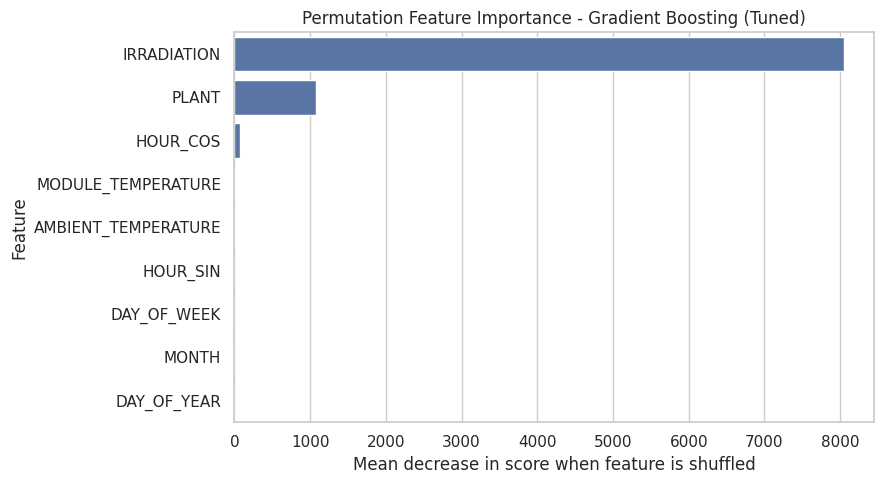

In [50]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
}).sort_values("Importance Mean", ascending=False)

display(feature_importance.round(5))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance,
    x="Importance Mean",
    y="Feature"
)
plt.title(f"Permutation Feature Importance - {best_model_name}")
plt.xlabel("Mean decrease in score when feature is shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 19. Final Interpretation, Business Insights and Limitations

Use the measured outputs from the preceding cells when writing the final interpretation. The notebook prints the selected model and its test metrics below so that the conclusion can be completed using actual results.

In [51]:
best_metrics = regression_metrics(y_test, best_predictions)

print("FINAL PROJECT SUMMARY")
print("---------------------")
print("Selected model:", best_model_name)
print(f"Test MAE:  {best_metrics['MAE']:.4f}")
print(f"Test RMSE: {best_metrics['RMSE']:.4f}")
print(f"Test R2:   {best_metrics['R2 Score']:.4f}")

print("\nTop three features by permutation importance:")
display(feature_importance.head(3)[["Feature", "Importance Mean"]].round(5))

FINAL PROJECT SUMMARY
---------------------
Selected model: Gradient Boosting (Tuned)
Test MAE:  554.2153
Test RMSE: 1333.6102
Test R2:   0.9647

Top three features by permutation importance:


,Feature,Importance Mean
0,IRRADIATION,8044.37489
8,PLANT,1078.55214
4,HOUR_COS,77.43475


### Business Insights

After reviewing the graphs and metrics, discuss:
- Which weather or time-related variables were most useful to estimate AC power.
- How average generation changed across the hours of the day.
- Whether the two plants showed different output patterns.
- How estimated power output could support basic generation planning and plant monitoring.

### Limitations

- The dataset covers a limited observation period and only two solar plants.
- Sensor measurements may contain missing values or measurement errors.
- The model may not generalise to other plants, locations or seasons.
- Weather and generation patterns in the test period may differ from future operating conditions.

### Future Improvements

- Use data collected over a longer period and across more solar plants.
- Include additional weather information such as cloud cover and wind speed, if available.
- Evaluate the model on a later time period or on a separate plant.
- Explore additional regression algorithms and more systematic feature engineering.

### Conclusion

The project demonstrates a complete supervised regression workflow for estimating solar plant AC power. The final conclusion should state the selected model, its measured MAE, RMSE and R², the most influential features, and the main limitation. Only include findings supported by the executed notebook results.